# neutron matter

In [ ]:
from tqdm import tqdm
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFpressurePNM, _set_couplings, RMFsolvePNM, RMFsolvePNM_mu, RMFedensPNM
from RMFsolver.phase_velocity import P_f, vNtoQ_nc, PQM, _find_muB_muK_star

n0 = 0.16 * const.MeV_fm**3
param = para.paraQMCRMF3
m_s = 0

def PNM(mu_B, Temp):
    pre = RMFpressurePNM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
        sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
        )
    return float(pre.item())


def PNM_n(nB, Temp):
    pre = RMFpressurePNM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
        sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
        )
    return float(pre.item())

def edensNM(mu_B, Temp):
    edens = RMFedensPNM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
        sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
        )
    return float(edens.item())

def edensNM_n(nB, Temp):
    edens = RMFedensPNM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
        sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
        )
    return float(edens.item())

def hNM(mu_B, Temp):
    return PNM(mu_B, Temp) + edensNM(mu_B, Temp)

def hNM_n(nB, Temp):
    return PNM_n(nB, Temp) + edensNM_n(nB, Temp)

In [7]:
edensNM(mu_B = 1000, Temp = 10)/1e9

1.7481275361519824

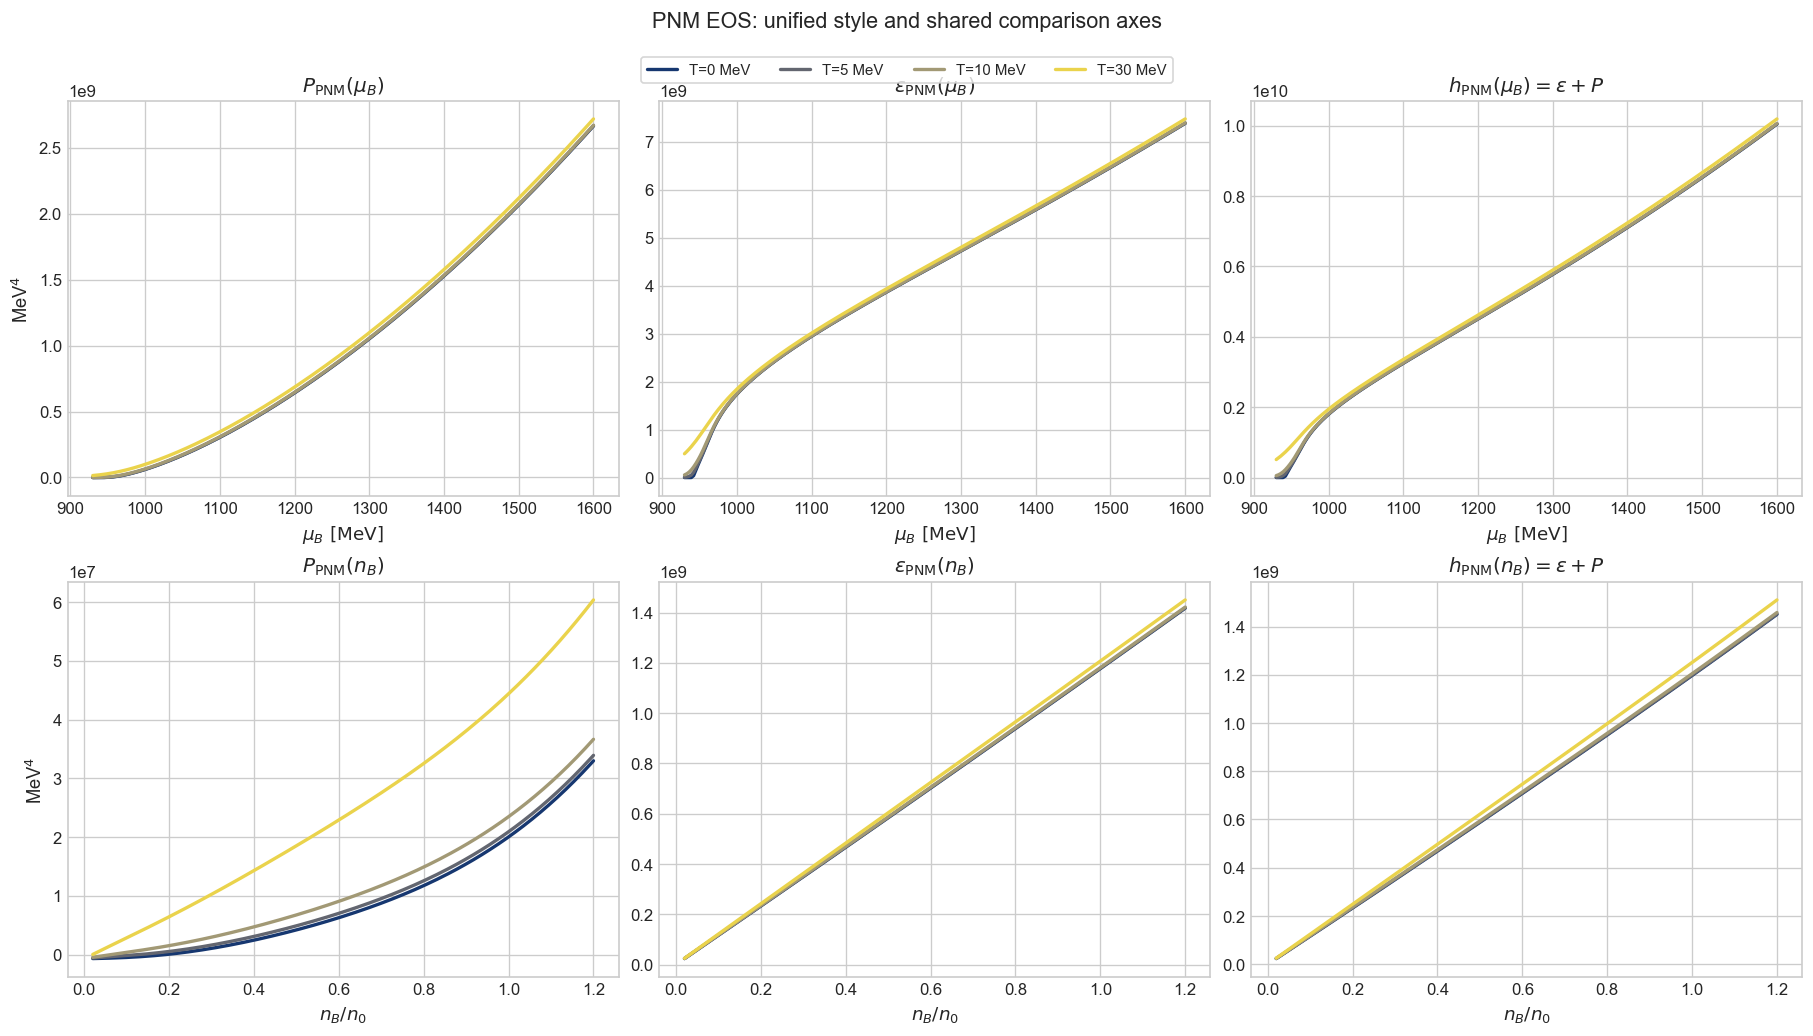

/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_51920/1059434424.py:129: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax[0].set_yscale('log')


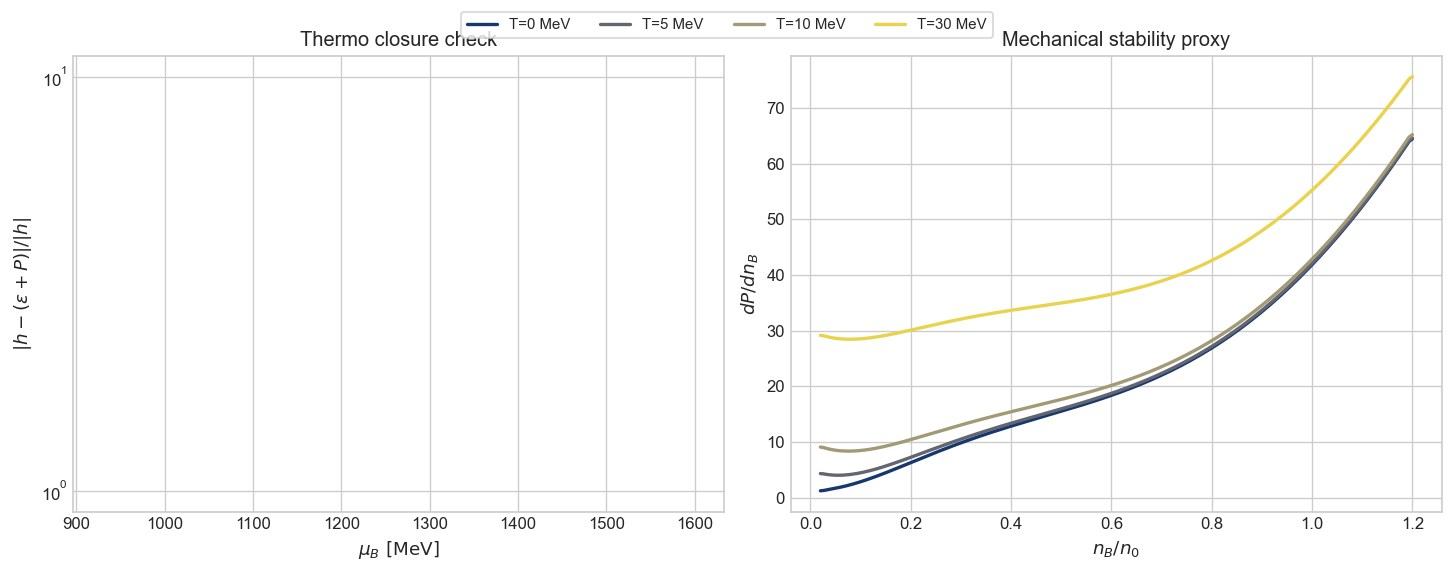

In [3]:
# Polished PNM diagnostics: tighter layout and cross-temperature comparability
import numpy as np
import matplotlib.pyplot as plt

# -------------------------
# Plot style
# -------------------------
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'legend.fontsize': 9,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'lines.linewidth': 2.0,
})

# -------------------------
# Controls
# -------------------------
Temps = [0.0, 5.0, 10.0, 30.0]
mu_min, mu_max, Nmu = 930.0, 1600.0, 220
n_min, n_max, Nn = 0.02 * n0, 1.20 * n0, 180

mu_grid = np.linspace(mu_min, mu_max, Nmu)
n_grid = np.linspace(n_min, n_max, Nn)


def safe_eval(func, x, T):
    try:
        return float(func(float(x), float(T)))
    except Exception:
        return np.nan


def finite_mask(*arrs):
    m = np.ones_like(arrs[0], dtype=bool)
    for arr in arrs:
        m &= np.isfinite(arr)
    return m


colors = plt.cm.cividis(np.linspace(0.12, 0.92, len(Temps)))

# -------------------------
# Precompute PNM grids
# -------------------------
pnm_mu = {}
pnm_n = {}

for T in Temps:
    P_mu = np.array([safe_eval(PNM, m, T) for m in mu_grid], dtype=float)
    eps_mu = np.array([safe_eval(edensNM, m, T) for m in mu_grid], dtype=float)
    h_mu = np.array([safe_eval(hNM, m, T) for m in mu_grid], dtype=float)

    rel_mu = np.full_like(mu_grid, np.nan, dtype=float)
    mmu = finite_mask(P_mu, eps_mu, h_mu)
    rel_mu[mmu] = (h_mu[mmu] - (eps_mu[mmu] + P_mu[mmu])) / np.maximum(1e-30, np.abs(h_mu[mmu]))

    pnm_mu[T] = {'P': P_mu, 'eps': eps_mu, 'h': h_mu, 'rel': rel_mu}

    P_n = np.array([safe_eval(PNM_n, n, T) for n in n_grid], dtype=float)
    eps_n = np.array([safe_eval(edensNM_n, n, T) for n in n_grid], dtype=float)
    h_n = np.array([safe_eval(hNM_n, n, T) for n in n_grid], dtype=float)

    dP_dn = np.full_like(P_n, np.nan, dtype=float)
    mgrad = np.isfinite(P_n)
    if np.count_nonzero(mgrad) > 3:
        dP_dn[mgrad] = np.gradient(P_n[mgrad], n_grid[mgrad])

    pnm_n[T] = {'P': P_n, 'eps': eps_n, 'h': h_n, 'dP_dn': dP_dn}

# -------------------------
# Figure 1: EOS vs mu_B and n_B
# -------------------------
fig, ax = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)

for c, T in zip(colors, Temps):
    y = pnm_mu[T]
    m = finite_mask(y['P'], y['eps'], y['h'])
    ax[0, 0].plot(mu_grid[m], y['P'][m], color=c, label=f'T={T:g} MeV')
    ax[0, 1].plot(mu_grid[m], y['eps'][m], color=c)
    ax[0, 2].plot(mu_grid[m], y['h'][m], color=c)

for c, T in zip(colors, Temps):
    y = pnm_n[T]
    x = n_grid / n0
    m = finite_mask(y['P'], y['eps'], y['h'])
    ax[1, 0].plot(x[m], y['P'][m], color=c, label=f'T={T:g} MeV')
    ax[1, 1].plot(x[m], y['eps'][m], color=c)
    ax[1, 2].plot(x[m], y['h'][m], color=c)

ax[0, 0].set_title(r'$P_{\rm PNM}(\mu_B)$')
ax[0, 1].set_title(r'$\epsilon_{\rm PNM}(\mu_B)$')
ax[0, 2].set_title(r'$h_{\rm PNM}(\mu_B)=\epsilon+P$')
ax[1, 0].set_title(r'$P_{\rm PNM}(n_B)$')
ax[1, 1].set_title(r'$\epsilon_{\rm PNM}(n_B)$')
ax[1, 2].set_title(r'$h_{\rm PNM}(n_B)=\epsilon+P$')

for j in range(3):
    ax[0, j].set_xlabel(r'$\mu_B\ [{\rm MeV}]$')
    ax[1, j].set_xlabel(r'$n_B/n_0$')

ax[0, 0].set_ylabel(r'MeV$^4$')
ax[1, 0].set_ylabel(r'MeV$^4$')

handles, labels = ax[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=len(Temps), frameon=True, bbox_to_anchor=(0.5, 1.02))
fig.suptitle('PNM EOS: unified style and shared comparison axes', y=1.06, fontsize=13)
plt.show()

# -------------------------
# Figure 2: consistency + stability diagnostics
# -------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

for c, T in zip(colors, Temps):
    rel = np.abs(pnm_mu[T]['rel'])
    m = np.isfinite(rel)
    ax[0].plot(mu_grid[m], rel[m], color=c, label=f'T={T:g} MeV')

for c, T in zip(colors, Temps):
    y = pnm_n[T]['dP_dn']
    x = n_grid / n0
    m = np.isfinite(y)
    ax[1].plot(x[m], y[m], color=c, label=f'T={T:g} MeV')

ax[0].set_yscale('log')
ax[0].set_xlabel(r'$\mu_B\ [{\rm MeV}]$')
ax[0].set_ylabel(r'$|h-(\epsilon+P)|/|h|$')
ax[0].set_title(r'Thermo closure check')

ax[1].set_xlabel(r'$n_B/n_0$')
ax[1].set_ylabel(r'$dP/dn_B$')
ax[1].set_title(r'Mechanical stability proxy')

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=len(Temps), frameon=True, bbox_to_anchor=(0.5, 1.04))
plt.show()


# quark matter

In [8]:
from RMFsolver.phase_velocity import P_f, PQM, PQM_em, E_f, edensQM

def hQM(muB, muK, B_one_forth, Temp):
    return PQM(muB, muK, B_one_forth, T=Temp, ms=0, upB=5000) + edensQM(muB, muK, B_one_forth, T=Temp, ms=0, include_em=False, muQ_init=300, upB=5000)

In [14]:
edensQM(muB=1000, muK=0, B_one_forth = 180, T=1)/1e9

3.864737333761015

/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:256: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)


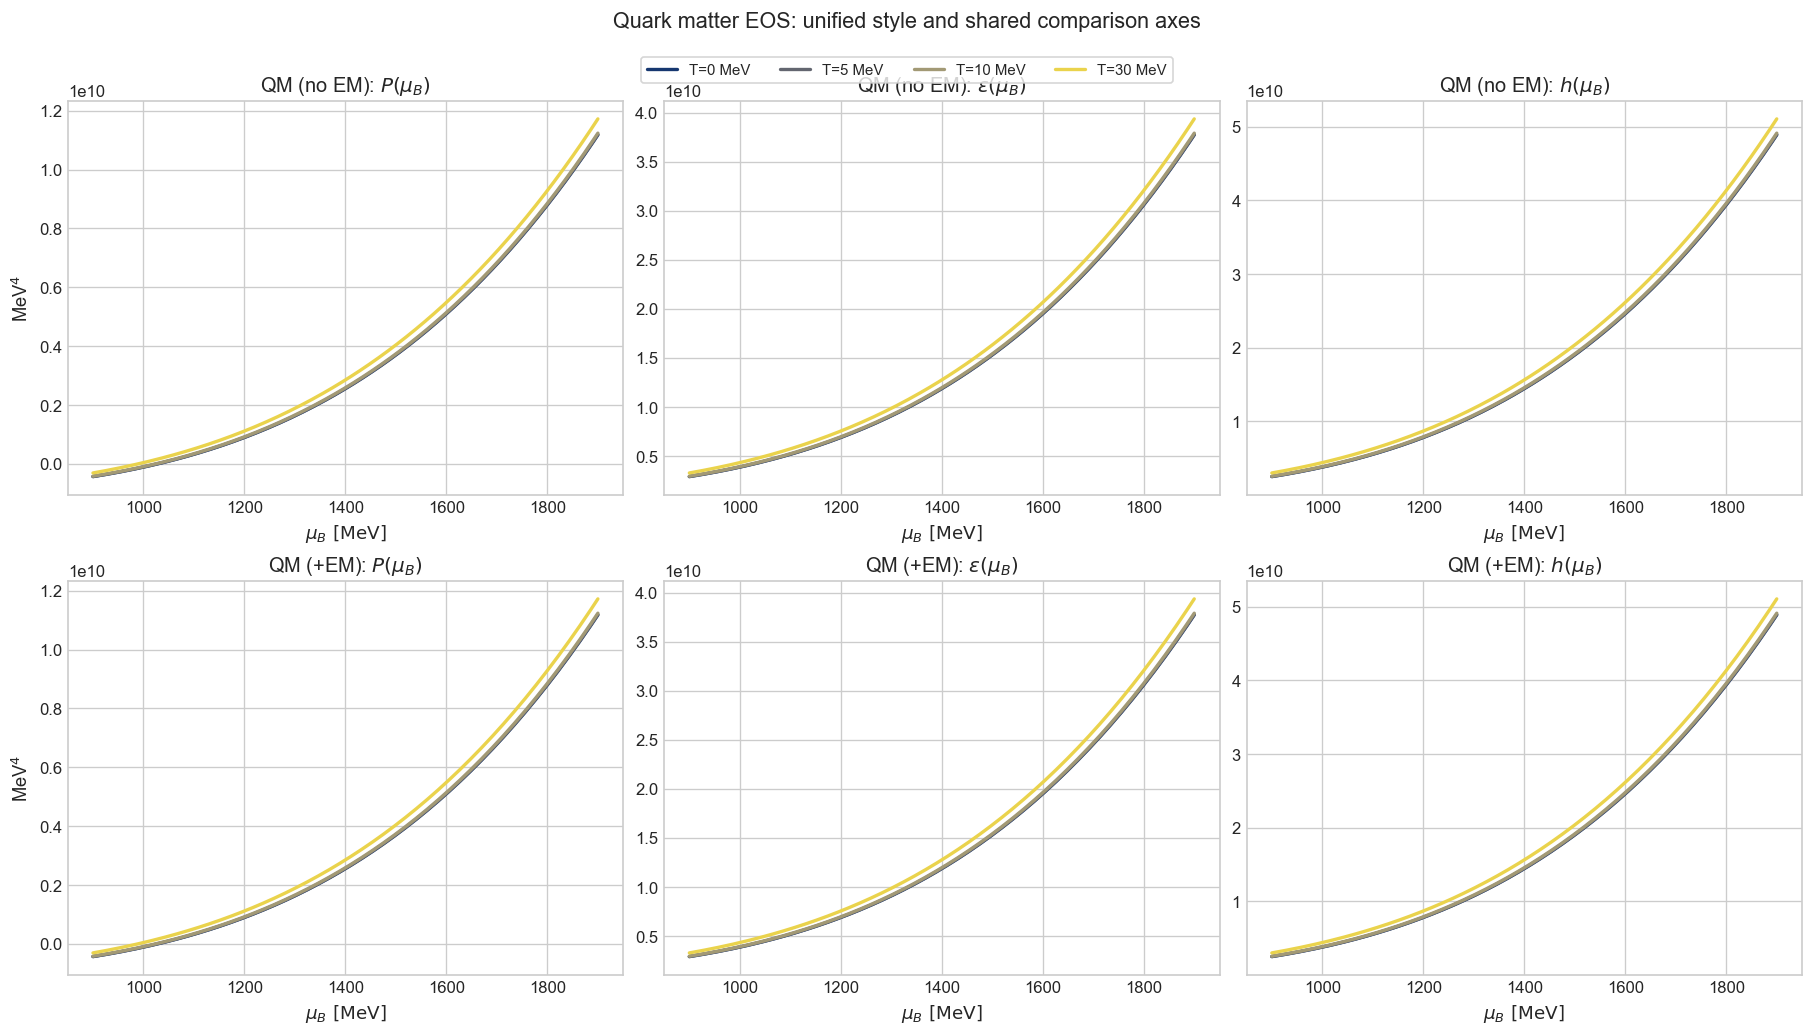

In [5]:
# Polished QM diagnostics (bag model): match PNM plotting style for easy comparison
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'legend.fontsize': 9,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'lines.linewidth': 2.0,
})

Temps_q = [0.0, 5.0, 10.0, 30.0]
muK_q = 0.0
B14_q = 180.0

# Reuse notebook-level strange-quark mass if present
ms_q = m_s if 'm_s' in globals() else 0.0

mu_min_q, mu_max_q, Nmu_q = 900.0, 1900.0, 220
mu_grid_q = np.linspace(mu_min_q, mu_max_q, Nmu_q)

# EM (charge-neutral solve) is heavier; use a slightly coarser grid
mu_grid_q_em = np.linspace(mu_min_q, mu_max_q, 140)


def safe_eval_qm(func, *args, **kwargs):
    try:
        val = func(*args, **kwargs)
        return float(np.asarray(val).item())
    except Exception:
        return np.nan


def finite_mask(*arrs):
    m = np.ones_like(arrs[0], dtype=bool)
    for arr in arrs:
        m &= np.isfinite(arr)
    return m


colors = plt.cm.cividis(np.linspace(0.12, 0.92, len(Temps_q)))

qm_noem = {}
for T in Temps_q:
    P = np.array([safe_eval_qm(PQM, mu, muK_q, B14_q, T, ms_q, 5000) for mu in mu_grid_q], dtype=float)
    eps = np.array([safe_eval_qm(edensQM, mu, muK_q, B14_q, T, ms_q, False, 300, 5000) for mu in mu_grid_q], dtype=float)
    h = P + eps
    qm_noem[T] = {'P': P, 'eps': eps, 'h': h}

qm_em = {}
for T in Temps_q:
    P = np.array([safe_eval_qm(PQM_em, mu, muK_q, B14_q, T, ms_q, 300, 5000) for mu in mu_grid_q_em], dtype=float)
    eps = np.array([safe_eval_qm(edensQM, mu, muK_q, B14_q, T, ms_q, True, 300, 5000) for mu in mu_grid_q_em], dtype=float)
    h = P + eps
    qm_em[T] = {'P': P, 'eps': eps, 'h': h}

fig, ax = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)

for c, T in zip(colors, Temps_q):
    y = qm_noem[T]
    m = finite_mask(y['P'], y['eps'], y['h'])
    ax[0, 0].plot(mu_grid_q[m], y['P'][m], color=c, label=f'T={T:g} MeV')
    ax[0, 1].plot(mu_grid_q[m], y['eps'][m], color=c)
    ax[0, 2].plot(mu_grid_q[m], y['h'][m], color=c)

for c, T in zip(colors, Temps_q):
    y = qm_em[T]
    m = finite_mask(y['P'], y['eps'], y['h'])
    ax[1, 0].plot(mu_grid_q_em[m], y['P'][m], color=c, label=f'T={T:g} MeV')
    ax[1, 1].plot(mu_grid_q_em[m], y['eps'][m], color=c)
    ax[1, 2].plot(mu_grid_q_em[m], y['h'][m], color=c)

ax[0, 0].set_title(r'QM (no EM): $P(\mu_B)$')
ax[0, 1].set_title(r'QM (no EM): $\epsilon(\mu_B)$')
ax[0, 2].set_title(r'QM (no EM): $h(\mu_B)$')
ax[1, 0].set_title(r'QM (+EM): $P(\mu_B)$')
ax[1, 1].set_title(r'QM (+EM): $\epsilon(\mu_B)$')
ax[1, 2].set_title(r'QM (+EM): $h(\mu_B)$')

for i in range(2):
    for j in range(3):
        ax[i, j].set_xlabel(r'$\mu_B\ [{\rm MeV}]$')
ax[0, 0].set_ylabel(r'MeV$^4$')
ax[1, 0].set_ylabel(r'MeV$^4$')

handles, labels = ax[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=len(Temps_q), frameon=True, bbox_to_anchor=(0.5, 1.02))
fig.suptitle('Quark matter EOS: unified style and shared comparison axes', y=1.06, fontsize=13)
plt.show()


In [9]:
# UPDATED_jB_over_nB: Pi uses u = j_B / n_B
from RMFsolver.Solver import RMFbaryon_densityPNM
from RMFsolver.phase_velocity import nQM

j_B = 2 * n0 * 1e-1

def nB_NM(mu_B, Temp):
    nB = RMFbaryon_densityPNM(
        input_num=mu_B,
        input_type="muB",
        Trmf=Temp,
        para=param,
        sigma_init=30,
        w0_init=20,
        r03_init=-3,
        mub_init=990,
        verb=False,
    )
    return float(np.asarray(nB).item())


def nB_QM(mu_B, mu_K, B_one_forth, Temp):
    nB = nQM(mu_B, mu_K, B_one_forth, T=Temp, ms=m_s, upB=5000)
    return float(np.asarray(nB).item())


def Pi_NM(mu_B, Temp, j_B=j_B):
    nB = nB_NM(mu_B, Temp)
    if nB <= 0:
        return np.nan
    uN = j_B / nB
    return hNM(mu_B, Temp) * uN * uN + PNM(mu_B, Temp)


def Pi_QM(mu_B, mu_K, B_one_forth, Temp, j_B=j_B):
    nB = nB_QM(mu_B, mu_K, B_one_forth, Temp)
    if nB <= 0:
        return np.nan
    uQ = j_B / nB
    return hQM(mu_B, mu_K, B_one_forth, Temp) * uQ * uQ + PQM(mu_B, mu_K, B_one_forth, Temp)


## Pi Balance In $(\mu_B, \mu_K)$ Plane

This section plots and compares $\Pi_{NM}$ and $\Pi_{QM}$, and overlays the balance contour where $\Pi_{NM}=\Pi_{QM}$.
We have two constraints: 
$$
n_B u = j_B = const.
$$ 
$$
\Pi = hu^2 + P = const.
$$ 
So take baryon flux as integral constant and plot 
$$
h_N\Big(\frac{j_B}{n_B^N}\Big)^2 + P_N = h_Q\Big(\frac{j_B}{n_B^Q}\Big)^2 + P_Q
$$
on the $(\mu_B, \mu_K)$ plane. 


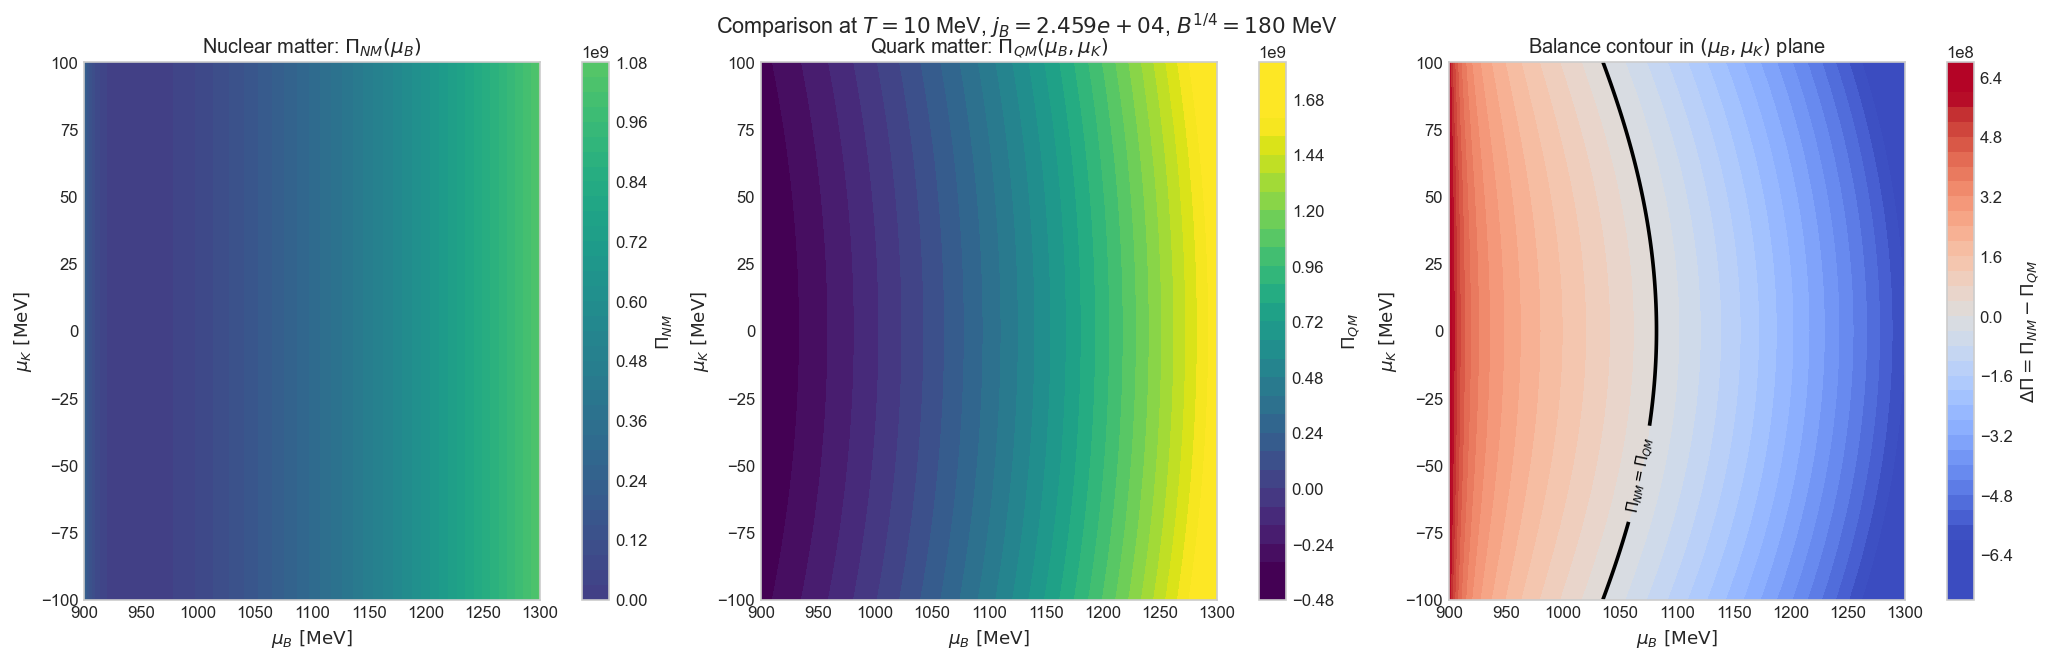

Valid Pi_QM points: 14641/14641
Pi_NM range: [3.89838e+06, 1.05653e+09]
Pi_QM range: [-4.18909e+08, 1.80204e+09]
DeltaPi range: [-7.45505e+08, 6.60187e+08]


In [2]:
# UPDATED_jB_over_nB: Pi_NM vs Pi_QM with u = j_B / n_B
# Uses exact signatures from this notebook:
#   Pi_NM(mu_B, Temp, j_B)
#   Pi_QM(mu_B, mu_K, B_one_forth, Temp, j_B)

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from RMFsolver.phase_velocity import Pi_NM, Pi_QM
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para

n0 = 0.16 * const.MeV_fm**3

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'lines.linewidth': 2.0,
})

# -------------------------
# Controls
# -------------------------
j_B_pi = 2 * n0 * 1e-2
Temp_pi = 10.0
B14_pi = 180.0

muB_min, muB_max, NmuB = 900.0, 1300.0, 121
muK_min, muK_max, NmuK = -100.0, 100.0, 121

muB_vals = np.linspace(muB_min, muB_max, NmuB)
muK_vals = np.linspace(muK_min, muK_max, NmuK)
MU_B, MU_K = np.meshgrid(muB_vals, muK_vals, indexing='xy')


def _to_float(x):
    return float(np.asarray(x).item())


# -------------------------
# Evaluate Pi_NM and Pi_QM on grid
# -------------------------
PiNM_1d = np.array([_to_float(Pi_NM(muB, Temp_pi, j_B=j_B_pi)) for muB in muB_vals], dtype=float)
PiNM = np.tile(PiNM_1d, (NmuK, 1))

PiQM = np.full_like(MU_B, np.nan, dtype=float)
for i, muK in enumerate(muK_vals):
    for j, muB in enumerate(muB_vals):
        try:
            PiQM[i, j] = _to_float(Pi_QM(muB, muK, B14_pi, Temp_pi, j_B=j_B_pi))
        except Exception:
            PiQM[i, j] = np.nan

DeltaPi = PiNM - PiQM
finite = np.isfinite(PiQM)
if not np.any(finite):
    raise RuntimeError('No valid Pi_QM points on grid. Check ranges / parameters.')

# Shared color scale for Pi_NM and Pi_QM to compare magnitudes directly
pi_all = np.concatenate([PiNM[np.isfinite(PiNM)], PiQM[np.isfinite(PiQM)]])
vmin_pi, vmax_pi = np.nanpercentile(pi_all, [2, 98])
if not np.isfinite(vmin_pi) or not np.isfinite(vmax_pi) or vmin_pi == vmax_pi:
    vmin_pi, vmax_pi = np.nanmin(pi_all), np.nanmax(pi_all)

# Centered scale for DeltaPi
d_finite = np.isfinite(DeltaPi)
abs_scale = np.nanpercentile(np.abs(DeltaPi[d_finite]), 95)
if not np.isfinite(abs_scale) or abs_scale <= 0:
    abs_scale = max(1.0, np.nanmax(np.abs(DeltaPi[d_finite])))

# -------------------------
# Plot and compare
# -------------------------
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2), constrained_layout=True)

cf0 = ax[0].contourf(MU_B, MU_K, PiNM, levels=35, cmap='viridis', vmin=vmin_pi, vmax=vmax_pi)
cb0 = fig.colorbar(cf0, ax=ax[0])
cb0.set_label(r'$\Pi_{NM}$')
ax[0].set_title(r'Nuclear matter: $\Pi_{NM}(\mu_B)$')
ax[0].set_xlabel(r'$\mu_B\ [{\rm MeV}]$')
ax[0].set_ylabel(r'$\mu_K\ [{\rm MeV}]$')

cf1 = ax[1].contourf(MU_B, MU_K, PiQM, levels=35, cmap='viridis', vmin=vmin_pi, vmax=vmax_pi)
cb1 = fig.colorbar(cf1, ax=ax[1])
cb1.set_label(r'$\Pi_{QM}$')
ax[1].set_title(r'Quark matter: $\Pi_{QM}(\mu_B,\mu_K)$')
ax[1].set_xlabel(r'$\mu_B\ [{\rm MeV}]$')
ax[1].set_ylabel(r'$\mu_K\ [{\rm MeV}]$')

norm_d = TwoSlopeNorm(vcenter=0.0, vmin=-abs_scale, vmax=abs_scale)
cf2 = ax[2].contourf(MU_B, MU_K, DeltaPi, levels=41, cmap='coolwarm', norm=norm_d)
cb2 = fig.colorbar(cf2, ax=ax[2])
cb2.set_label(r'$\Delta\Pi=\Pi_{NM}-\Pi_{QM}$')

c0 = ax[2].contour(MU_B, MU_K, DeltaPi, levels=[0.0], colors='k', linewidths=2.2)
if len(c0.allsegs[0]) > 0:
    ax[2].clabel(c0, fmt={0.0: r'$\Pi_{NM}=\Pi_{QM}$'}, inline=True, fontsize=9)
else:
    ax[2].text(0.03, 0.96, 'No zero contour on this grid', transform=ax[2].transAxes,
               va='top', ha='left', fontsize=9,
               bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

ax[2].set_title(r'Balance contour in $(\mu_B,\mu_K)$ plane')
ax[2].set_xlabel(r'$\mu_B\ [{\rm MeV}]$')
ax[2].set_ylabel(r'$\mu_K\ [{\rm MeV}]$')

fig.suptitle(fr'Comparison at $T={Temp_pi:g}$ MeV, $j_B={j_B_pi:.3e}$, $B^{{1/4}}={B14_pi:g}$ MeV', y=1.03, fontsize=13)
plt.show()

print(f'Valid Pi_QM points: {np.count_nonzero(finite)}/{finite.size}')
print(f'Pi_NM range: [{np.nanmin(PiNM):.6g}, {np.nanmax(PiNM):.6g}]')
print(f'Pi_QM range: [{np.nanmin(PiQM):.6g}, {np.nanmax(PiQM):.6g}]')
print(f'DeltaPi range: [{np.nanmin(DeltaPi):.6g}, {np.nanmax(DeltaPi):.6g}]')


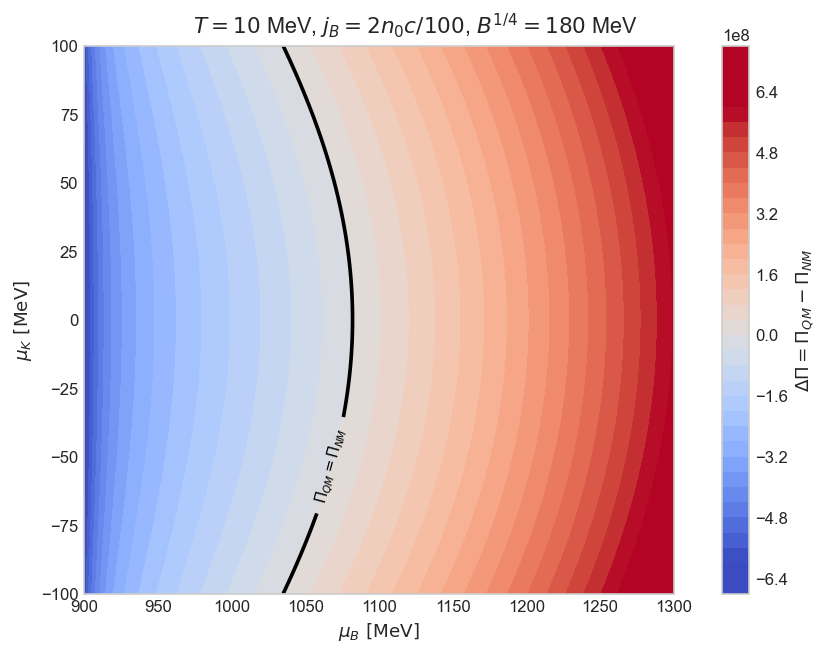

Valid Pi_QM points: 14641/14641
DeltaPi range: [-7.45505e+08, 6.60187e+08]


In [25]:
# -------------------------
# Plot ONLY DeltaPi contour
# -------------------------
fig, ax = plt.subplots(figsize=(6.8, 5.2), constrained_layout=True)

norm_d = TwoSlopeNorm(vcenter=0.0, vmin=-abs_scale, vmax=abs_scale)

cf = ax.contourf(MU_B, MU_K, -DeltaPi, levels=41, cmap='coolwarm', norm=norm_d)
cb = fig.colorbar(cf, ax=ax)
cb.set_label(r'$\Delta\Pi=\Pi_{QM}-\Pi_{NM}$')

# Zero contour
c0 = ax.contour(MU_B, MU_K, DeltaPi, levels=[0.0], colors='k', linewidths=2.2)

if len(c0.allsegs[0]) > 0:
    ax.clabel(c0, fmt={0.0: r'$\Pi_{QM}=\Pi_{NM}$'}, inline=True, fontsize=9)
else:
    ax.text(0.03, 0.96, 'No zero contour on this grid',
            transform=ax.transAxes,
            va='top', ha='left', fontsize=9,
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

# Keep only axis labels
ax.set_xlabel(r'$\mu_B\ [{\rm MeV}]$')
ax.set_ylabel(r'$\mu_K\ [{\rm MeV}]$')

# Keep parameter summary as before
fig.suptitle(
    fr'$T={Temp_pi:g}$ MeV, '
    fr'$j_B=2n_0 c/100$, ' # {j_B_pi:.3e}
    fr'$B^{{1/4}}={B14_pi:g}$ MeV',
    y=1.02,
    fontsize=13
)

plt.show()

print(f'Valid Pi_QM points: {np.count_nonzero(finite)}/{finite.size}')
print(f'DeltaPi range: [{np.nanmin(DeltaPi):.6g}, {np.nanmax(DeltaPi):.6g}]')

In [1]:
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.phase_velocity import _find_Qstar

n0 = 0.16 * const.MeV_fm**3
param = para.paraQMCRMF3
m_s = 0

_find_Qstar(T = 10, B_one_forth = 180, lambda_val = 0.5, jB = n0 * 1e-3, Pi = 3e8)

(1089.1954450191608, 30.862141981305243)

In [1]:
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.phase_velocity import _find_Qstar

n0 = 0.16 * const.MeV_fm**3
param = para.paraQMCRMF3
m_s = 0

_find_Qstar(T = 10, B_one_forth = 180, lambda_val = 0.5, jB = n0 * 1e-3, Pi = 3e8)

(1087.8884969428655, 39.88048851149362)

In [1]:
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.phase_velocity import uQ_uN

n0 = 0.16 * const.MeV_fm**3
param = para.paraQMCRMF3
m_s = 0

uQ, uN = uQ_uN(T = 10, B_one_forth = 180, lambda_val = 0.5, jB = n0 * 1e-5, Pi_over_crit = 2)

In [2]:
uQ/3e3, uN/3e3

(0.6754531303832743, 0.3520966111820366)

In [12]:
uQ/3e3, uN/3e3

(0.3332040914999446, 0.18665573666691412)

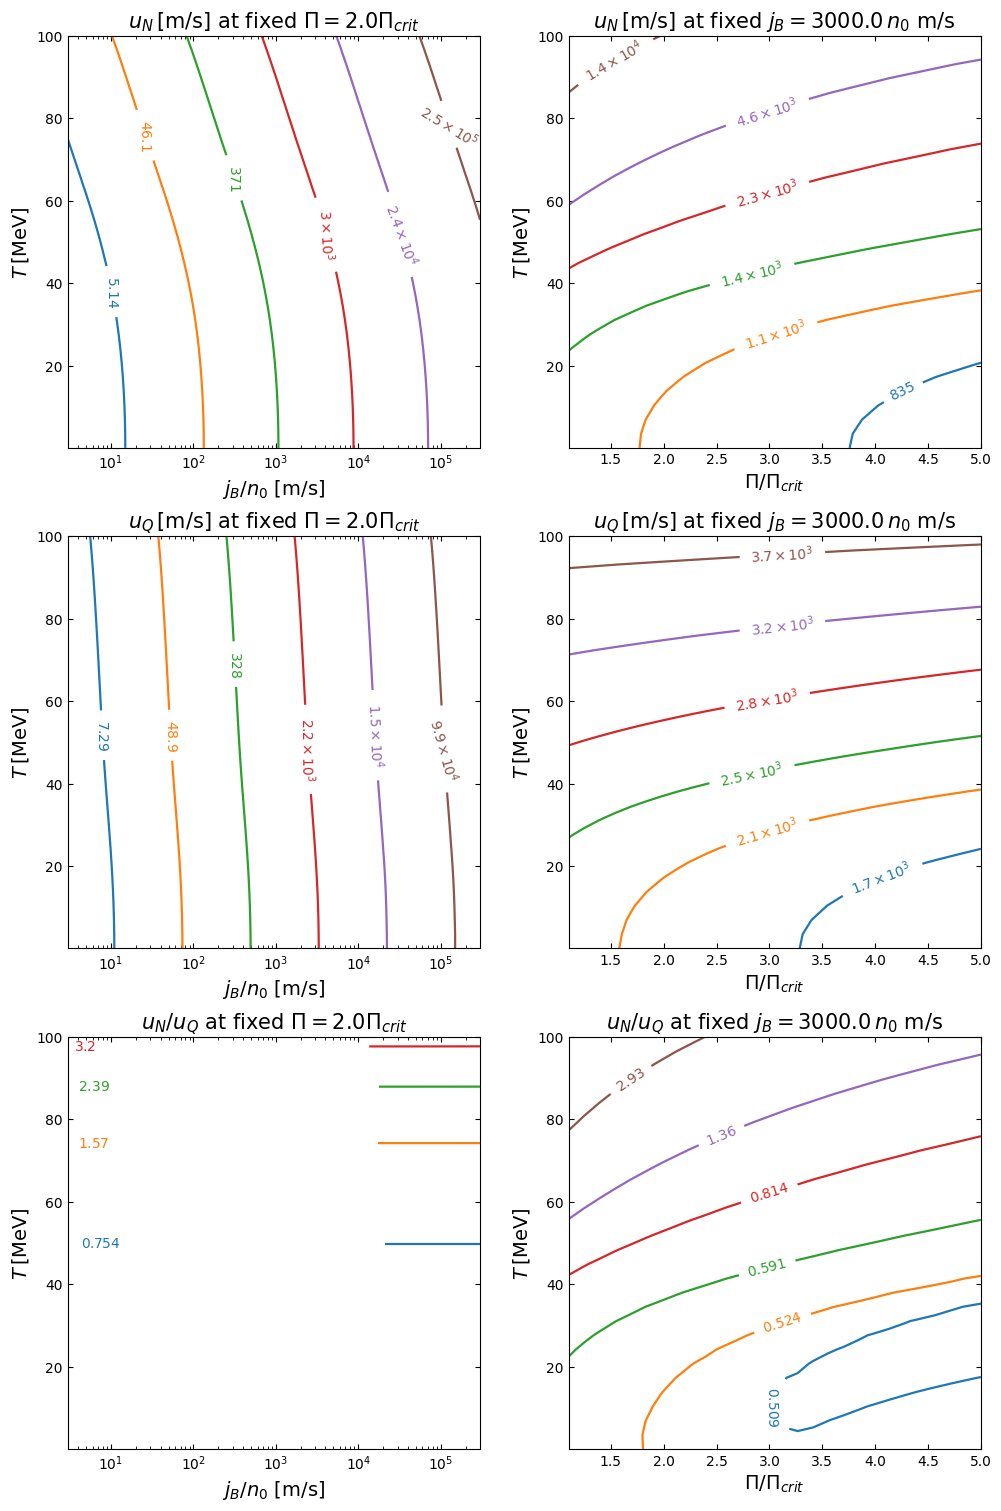

Loaded fixed-Pi_over_crit slice from: uQ_uN_contour_T_jB__v2.npz
Loaded fixed-jB slice from: uQ_uN_contour_T_Pi__v2.npz
ratio_jB_T shape = (30, 28), expected = (30, 28)
ratio_Pi_T shape = (30, 28), expected = (30, 28)
ratio_jB_T_dense shape = (30, 240), expected = (30, 240)
bottom-left common overlap range = [0.5209, 3.4371]
bottom-left chosen full-width levels = [0.75419367 1.57071602 2.38723837 3.20376072]


In [5]:
# FORCE_UPDATE_CONTOUR_GEOMETRY_2026-03-19_B
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from pathlib import Path
from scipy.interpolate import interp1d
import RMFsolver.constants as const

# ------------------ constants ------------------
n0 = 0.16 * const.MeV_fm**3
c_light = 3e8  # m/s
VERSION = "v2"

# ------------------ robust data loading ------------------
def load_npz_with_fallback(*names):
    for name in names:
        path = Path(name)
        if path.exists():
            return np.load(path), path.name
    raise FileNotFoundError(f"Could not find any of: {names}")


data_T_jB, file_T_jB = load_npz_with_fallback(
    f"uQ_uN_contour_T_jB__{VERSION}.npz",
)

data_T_Pi, file_T_Pi = load_npz_with_fallback(
    f"uQ_uN_contour_T_Pi_over_crit__{VERSION}.npz",
    f"uQ_uN_contour_T_Pi__{VERSION}.npz",
)

TT = np.asarray(data_T_jB["TT"], dtype=float)
jB_list = np.asarray(data_T_jB["jB_list"], dtype=float)
Pi_over_crit_fixed = float(data_T_jB["Pi_over_crit_fixed"]) if "Pi_over_crit_fixed" in data_T_jB else float(data_T_jB["Pi_fixed"])
uQ_T_jB = np.asarray(data_T_jB["uQ"], dtype=float)
uN_T_jB = np.asarray(data_T_jB["uN"], dtype=float)

Pi_over_crit_list = np.asarray(data_T_Pi["Pi_over_crit_list"], dtype=float) if "Pi_over_crit_list" in data_T_Pi else np.asarray(data_T_Pi["Pi_list"], dtype=float)
jB_fixed = float(data_T_Pi["jB_fixed"])
uQ_T_Pi = np.asarray(data_T_Pi["uQ"], dtype=float)
uN_T_Pi = np.asarray(data_T_Pi["uN"], dtype=float)

# ------------------ derived ratio fields ------------------
with np.errstate(divide="ignore", invalid="ignore"):
    ratio_T_jB = uN_T_jB / uQ_T_jB
    ratio_T_Pi = uN_T_Pi / uQ_T_Pi

ratio_T_jB[~np.isfinite(ratio_T_jB)] = np.nan
ratio_T_Pi[~np.isfinite(ratio_T_Pi)] = np.nan

# ------------------ rescale jB ------------------
jB_scaled = jB_list * c_light / n0
jB_fixed_scaled = jB_fixed * c_light / n0

# ------------------ palette ------------------
tab20 = plt.get_cmap("tab20").colors
sat = [tab20[i] for i in [0, 2, 4, 6, 8, 10, 12, 14, 16, 18]]
tab20b = plt.get_cmap("tab20b").colors
tab20c = plt.get_cmap("tab20c").colors
palette = sat + list(tab20b[::2]) + list(tab20c[::2])
cmap = ListedColormap(palette, name="tab20_bright")

def pick_colors(n):
    return [cmap.colors[i % len(cmap.colors)] for i in range(n)]

# ------------------ contour helper ------------------
def choose_levels(Z, nlev=6, mode="auto", qlo=8, qhi=92):
    z = np.ma.masked_invalid(np.asarray(Z, dtype=float)).compressed()
    if z.size < nlev + 2:
        raise ValueError("Not enough finite values to build contour levels.")

    zmin = np.nanmin(z)
    zmax = np.nanmax(z)
    lo = np.percentile(z, qlo)
    hi = np.percentile(z, qhi)

    if not np.isfinite(lo) or not np.isfinite(hi) or lo >= hi:
        lo, hi = zmin, zmax

    if mode == "linear":
        return np.linspace(lo, hi, nlev)

    if mode == "geom":
        if np.any(z > 0):
            lo_pos = max(lo, np.min(z[z > 0]))
            return np.geomspace(lo_pos, hi, nlev)
        return np.linspace(lo, hi, nlev)

    if mode == "quantile":
        levels = np.percentile(z, np.linspace(qlo, qhi, nlev))
        levels = np.unique(levels)
        if len(levels) < 3:
            return np.linspace(lo, hi, nlev)
        return levels

    if lo > 0 and hi / lo > 20:
        return np.geomspace(lo, hi, nlev)
    return np.linspace(lo, hi, nlev)


def nice_fmt(x):
    if x == 0:
        return r"$0$"
    exp = int(np.floor(np.log10(abs(x))))
    if exp >= 3 or exp <= -2:
        mant = x / (10 ** exp)
        mant_str = f"{mant:.2g}"
        if mant_str == "1":
            return rf"$10^{{{exp}}}$"
        return rf"${mant_str}\times10^{{{exp}}}$"
    return rf"${x:.3g}$"


def contour_panel(
    ax,
    x,
    y,
    Z,
    xlabel,
    ylabel,
    title,
    xscale="linear",
    yscale="linear",
    level_mode="auto",
    nlev=6,
    qlo=8,
    qhi=92,
    levels=None,
):
    Zm = np.ma.masked_invalid(np.asarray(Z, dtype=float))
    if levels is None:
        levels = choose_levels(Zm, nlev=nlev, mode=level_mode, qlo=qlo, qhi=qhi)

    cs = ax.contour(
        x,
        y,
        Zm,
        levels=levels,
        colors=pick_colors(len(levels)),
        linewidths=1.6,
        corner_mask=False,
    )
    ax.clabel(cs, inline=True, fontsize=10, fmt=nice_fmt)
    ax.set_xscale(xscale)
    ax.set_yscale(yscale)
    ax.set_xlabel(xlabel, fontsize=14)
    ax.set_ylabel(ylabel, fontsize=14)
    ax.set_title(title, fontsize=15)
    ax.tick_params(which="both", direction="in", top=True, right=True)
    ax.set_box_aspect(1)

# ------------------ native orientation ------------------
ratio_jB_T = ratio_T_jB.copy()
ratio_Pi_T = ratio_T_Pi.copy()

# ------------------ dense interpolation only for bottom-left panel ------------------
logjB = np.log10(jB_scaled)
logjB_dense = np.linspace(logjB.min(), logjB.max(), 240)
jB_scaled_dense = 10**logjB_dense

ratio_jB_T_dense = np.full((TT.size, jB_scaled_dense.size), np.nan, dtype=float)
for i in range(TT.size):
    row = ratio_jB_T[i]
    mask = np.isfinite(row)
    if np.count_nonzero(mask) >= 2:
        f = interp1d(
            logjB[mask],
            row[mask],
            kind="linear",
            bounds_error=False,
            fill_value=np.nan,
            assume_sorted=True,
        )
        ratio_jB_T_dense[i] = f(logjB_dense)

# ------------------ full-width levels for bottom-left panel ------------------
# Use only levels that lie in the common overlap across all jB columns.
col_mins = np.nanmin(ratio_jB_T_dense, axis=0)
col_maxs = np.nanmax(ratio_jB_T_dense, axis=0)

common_lo = np.nanmax(col_mins)
common_hi = np.nanmin(col_maxs)

# Back off a little from the edges to avoid touching noisy extrema.
pad = 0.08 * (common_hi - common_lo)
common_lo_use = common_lo + pad
common_hi_use = common_hi - pad

# Choose a few levels so every one is expected to run across the panel.
ratio_jB_levels = np.linspace(common_lo_use, common_hi_use, 4)

# ------------------ plot ------------------
fig, axes = plt.subplots(3, 2, figsize=(10, 15), constrained_layout=True)

contour_panel(
    axes[0, 0],
    jB_scaled,
    TT,
    uN_T_jB,
    xlabel=r"$j_B / n_0$ [m/s]",
    ylabel=r"$T\,[\mathrm{MeV}]$",
    title=rf"$u_N\,[\mathrm{{m/s}}]$ at fixed $\Pi={Pi_over_crit_fixed:.1f}\Pi_{{crit}}$",
    xscale="log",
    level_mode="quantile",
    nlev=6,
    qlo=8,
    qhi=96,
)

contour_panel(
    axes[0, 1],
    Pi_over_crit_list,
    TT,
    uN_T_Pi,
    xlabel=fr"$\Pi/\Pi_{{crit}}$",
    ylabel=r"$T\,[\mathrm{MeV}]$",
    title=rf"$u_N\,[\mathrm{{m/s}}]$ at fixed $j_B={jB_fixed_scaled:.1f}\,n_0$ m/s",
    level_mode="quantile",
    nlev=6,
    qlo=5,
    qhi=98,
)

contour_panel(
    axes[1, 0],
    jB_scaled,
    TT,
    uQ_T_jB,
    xlabel=r"$j_B / n_0$ [m/s]",
    ylabel=r"$T\,[\mathrm{MeV}]$",
    title=rf"$u_Q\,[\mathrm{{m/s}}]$ at fixed $\Pi={Pi_over_crit_fixed:.1f}\Pi_{{crit}}$",
    xscale="log",
    level_mode="geom",
    nlev=6,
    qlo=10,
    qhi=90,
)

contour_panel(
    axes[1, 1],
    Pi_over_crit_list,
    TT,
    uQ_T_Pi,
    xlabel=fr"$\Pi/\Pi_{{crit}}$",
    ylabel=r"$T\,[\mathrm{MeV}]$",
    title=rf"$u_Q\,[\mathrm{{m/s}}]$ at fixed $j_B={jB_fixed_scaled:.1f}\,n_0$ m/s",
    level_mode="quantile",
    nlev=6,
    qlo=8,
    qhi=94,
)

contour_panel(
    axes[2, 0],
    jB_scaled_dense,
    TT,
    ratio_jB_T_dense,
    xlabel=r"$j_B / n_0$ [m/s]",
    ylabel=r"$T\,[\mathrm{MeV}]$",
    title=rf"$u_N/u_Q$ at fixed $\Pi={Pi_over_crit_fixed:.1f}\Pi_{{crit}}$",
    xscale="log",
    levels=ratio_jB_levels,
)

contour_panel(
    axes[2, 1],
    Pi_over_crit_list,
    TT,
    ratio_Pi_T,
    xlabel=fr"$\Pi/\Pi_{{crit}}$",
    ylabel=r"$T\,[\mathrm{MeV}]$",
    title=rf"$u_N/u_Q$ at fixed $j_B={jB_fixed_scaled:.1f}\,n_0$ m/s",
    level_mode="quantile",
    nlev=6,
    qlo=8,
    qhi=96,
)

plt.savefig(f"uQ_uN_ratio_contours__{VERSION}.pdf", bbox_inches="tight")
plt.show()

print(f"Loaded fixed-Pi_over_crit slice from: {file_T_jB}")
print(f"Loaded fixed-jB slice from: {file_T_Pi}")
print(f"ratio_jB_T shape = {ratio_jB_T.shape}, expected = ({TT.size}, {jB_scaled.size})")
print(f"ratio_Pi_T shape = {ratio_Pi_T.shape}, expected = ({TT.size}, {Pi_over_crit_list.size})")
print(f"ratio_jB_T_dense shape = {ratio_jB_T_dense.shape}, expected = ({TT.size}, {jB_scaled_dense.size})")
print(f"bottom-left common overlap range = [{common_lo:.4f}, {common_hi:.4f}]")
print(f"bottom-left chosen full-width levels = {ratio_jB_levels}")

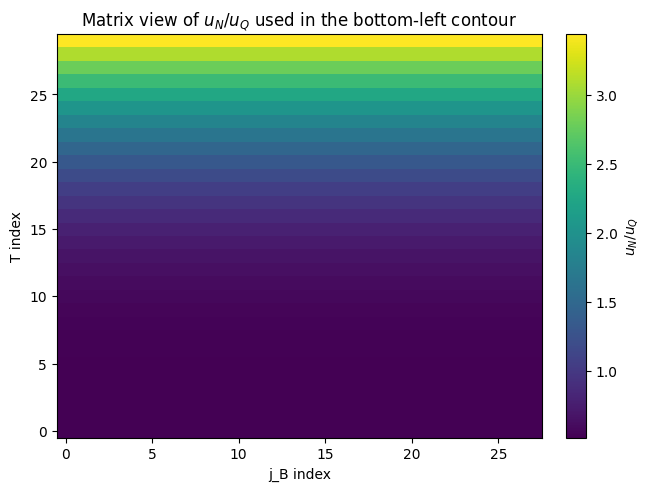

ratio_jB_T max = 3.43921
ratio_jB_T min = 0.519211


In [16]:
# FORCE_UPDATE_RATIO_DEBUG_2026-03-19_B
fig, ax = plt.subplots(figsize=(6.4, 4.8), constrained_layout=True)

im = ax.imshow(
    ratio_jB_T,
    origin="lower",
    aspect="auto",
    cmap="viridis",
)
cb = fig.colorbar(im, ax=ax)
cb.set_label(r"$u_N/u_Q$")

ax.set_xlabel("j_B index")
ax.set_ylabel("T index")
ax.set_title(r"Matrix view of $u_N/u_Q$ used in the bottom-left contour")

plt.show()

print(f"ratio_jB_T max = {np.nanmax(ratio_jB_T):.6g}")
print(f"ratio_jB_T min = {np.nanmin(ratio_jB_T):.6g}")


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from pathlib import Path
from scipy.interpolate import interp1d
import RMFsolver.constants as const
from RMFsolver.phase_velocity import uN

n0 = 0.16 * const.MeV_fm**3

uN(T=10, nB_N=2*n0, Delta_n=0.1*n0, B_one_forth=220)

(187919459.79787153, 194677.14711990877, 0.07917821727755568)

In [22]:
from tqdm import tqdm
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
from RMFsolver.phase_velocity import PNM, PNM_n, edensNM, edensNM_n, hNM, hNM_n, nB_NM, Pi_NM
from RMFsolver.phase_velocity import PQM, nB_QM, edensQM, hQM, Pi_QM

T = 10
nB_N = 3*n0
B = 180

P_N = PNM_n(nB_N, T)
muB_inf = fsolve(lambda x: PQM(x, 0.0, B, T)-P_N, 1100)[0]
nB_inf = nB_QM(muB_inf, 0.0, B, T)

h_N = hNM_n(nB_N, T)
h_inf = hQM(muB_inf, 0.0, B, T)

h_ratio = h_N / h_inf
nB_ratio_square = (nB_N / nB_inf)**2

h_ratio/nB_ratio_square

0.1782954754065329

In [23]:
(h_N / (nB_N)**2) / (h_inf / (nB_inf)**2)

0.17829547540653296

## Steady Front Example

Example call to `solve_steady_front_2d(...)` that prints the shooting summary and, if the solver converges, plots $a(x)$, $q(x)$, and $u(x)$.

If the solve does not converge on the first try, keep the cell and tune `jB_guess`, `aQstar_guess`, `x_max`, and `n_eval`.


In [4]:
# FORCE_UPDATE_STEADY_FRONT_EXAMPLE_2026-03-31_D
import RMFsolver.constants as const
from RMFsolver.phase_velocity import solve_steady_front_2d

n0 = 0.16 * const.MeV_fm**3

T_example = 10.0
nB_N_example = 2.0 * n0
B14_example = 180.0

# Rich-branch guess from the previous cluster scan, now rerun on a much longer domain.
front_result = solve_steady_front_2d(
    T=T_example,
    nB_N=nB_N_example,
    B_one_forth=B14_example,
    x_max=5.0e6,
    n_eval=300,
    root_tol=1e-5,
    max_nfev=60,
    jB_guess=0.485015,
    aQstar_guess=0.177496,
    return_profile=True,
    verb=True,
)

print(f"success: {front_result['success']}")
print(f"message: {front_result['message']}")
print(f"jB: {front_result['jB']:.6g}")
print(f"u_N: {front_result['u_N']:.6g}")
print(f"a_N: {front_result['a_N']:.6g}")
print(f"aQstar: {front_result['aQstar']:.6g}")
print(f"Pi: {front_result['Pi']:.6g}")
print(f"muB_Qstar: {front_result['muB_Qstar']:.6g}")
print(f"muK_Qstar: {front_result['muK_Qstar']:.6g}")
print(f"muB_Q: {front_result['muB_Q']:.6g}")
print(f"nB_Q: {front_result['nB_Q']:.6g}")
print(f"nK_Q: {front_result['nK_Q']:.6g}")
print(f"DQ: {front_result['DQ']:.6g}")
print(f"eta: {front_result['eta']:.6g}")
print(f"gamma: {front_result['gamma']:.6g}")
print(f"tau: {front_result['tau']:.6g}")
print(f"a_end: {front_result['a_end']:.6g}")
print(f"q_end: {front_result['q_end']:.6g}")

if front_result['success'] and all(k in front_result for k in ['x', 'a', 'q', 'u']):
    fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True, constrained_layout=True)

    axes[0].plot(front_result['x'], front_result['a'], lw=2.0)
    axes[0].set_ylabel(r'$a(x)$')
    axes[0].set_title('Steady front profile')

    axes[1].plot(front_result['x'], front_result['q'], lw=2.0)
    axes[1].set_ylabel(r'$q(x)$')

    axes[2].plot(front_result['x'], front_result['u'], lw=2.0)
    axes[2].set_ylabel(r'$u(x)$')
    axes[2].set_xlabel(r'$x$')

    plt.show()
else:
    print('No profile plotted. The solver now prints stage diagnostics because verb=True.')
    print('If needed, tune jB_guess, aQstar_guess, x_max, or n_eval and rerun.')



shoot jB=0.581728, aQstar=0.145148, res=(-0.081511, -3.81974e-07), ok=True
shoot jB=0.581728, aQstar=0.145148, res=(-0.081511, -3.81974e-07), ok=True
shoot jB=0.581728, aQstar=0.145148, res=(-0.081511, -3.81974e-07), ok=True
shoot jB=0.581728, aQstar=0.145148, res=(-0.0815111, -3.81974e-07), ok=True
shoot jB=0.581728, aQstar=0.145148, res=(-0.0815111, -3.81974e-07), ok=True
shoot jB=0.221338, aQstar=0.412544, res=(0.367437, -1.15499e-07), ok=True
shoot jB=0.360408, aQstar=0.280062, res=(0.170477, -2.27442e-07), ok=True
shoot jB=0.581728, aQstar=0.145148, res=(-0.0815111, -3.81974e-07), ok=True
shoot jB=0.581728, aQstar=0.145148, res=(-0.0815111, -3.81974e-07), ok=True
shoot jB=0.221338, aQstar=0.412544, res=(0.367437, -1.15499e-07), ok=True
shoot jB=0.360408, aQstar=0.280062, res=(0.170477, -2.27442e-07), ok=True
shoot jB=0.458516, aQstar=0.212981, res=(0.05411, -2.97382e-07), ok=True
shoot jB=0.287772, aQstar=0.351355, res=(0.277625, -1.70709e-07), ok=True
shoot jB=0.365175, aQstar=0.

## Cluster Steady-Front Results

This section loads the oldest usable short-domain cluster `steady_front_run_*` folder from `new_paper_calculations/26-03-31` (targeting the runs with `L_max` around 50 nm), summarizes the shooting results, and compares representative profile branches.

Working split used below:
- `muK`-poor branch: `max_x |mu_K(x)| < 1e-3 MeV`
- `muK`-rich branch: otherwise



Using latest cluster run: steady_front_run_20260405_155749
Selected run: steady_front_run_20260405_155749
T = 10.0 MeV, nB_N = 2.0 n0, B^(1/4) = 180.0 MeV
x_max = 1.000e+06, n_eval = 300, root_tol = 1e-05, max_nfev = 60
x_max ~= 197.327 nm
Trials with saved profiles: 3
Successful saved-profile trials: 1/3
Plotting successful trials only: 1
muK-poor plotted trials: 0, muK-rich plotted trials: 1
Top trials by |a_end| + |q_end|:
  trial  2: merit=7.012e-07, jB=0.498211, aQstar=0.189325, muKmax=4.530e+01, branch=rich, a_end=6.017e-07, q_end=-9.949e-08

Analytic aQstar diagnostic:
  trial  2: muK-rich, jB/n0=121.494 m/s, aQstar=0.189325, aQstar_approx=0.418465, rel.diff=1.210e+00, lambda=3.119e-07

Relative-difference summary: median=1.210e+00, mean=1.210e+00, max=1.210e+00
Saved figure: /Users/janshao/NSM_related/new_paper_calculations/26-03-31/shooting_summary.pdf


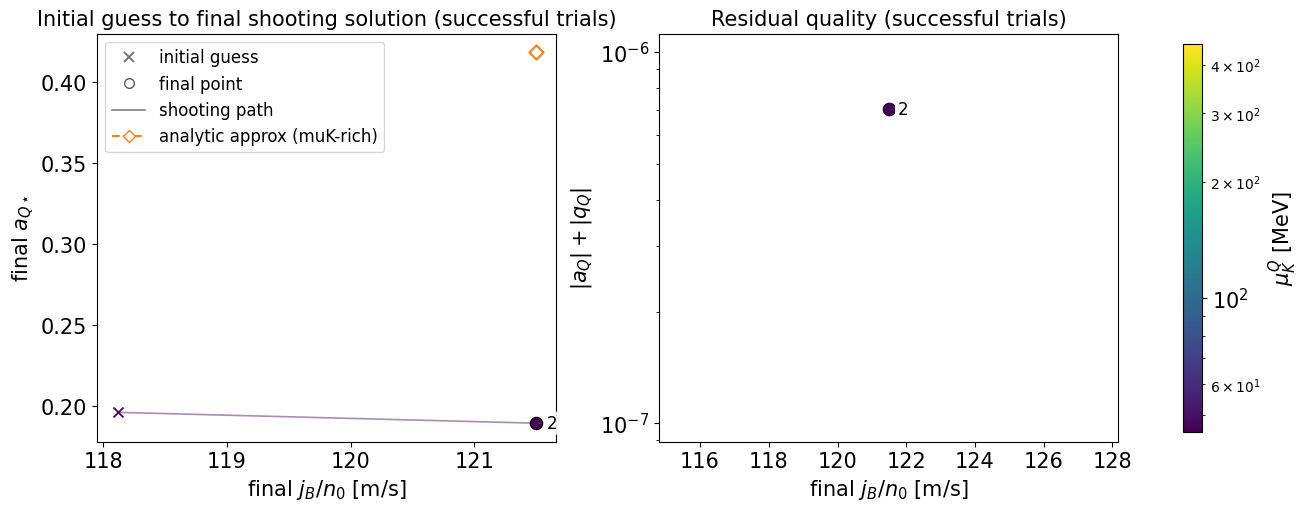

Loaded 1 successful trial rows from steady_front_run_20260405_155749 (saved profiles: 3)
Working trials: [2]


In [2]:
# FORCE_UPDATE_CLUSTER_RESULTS_2026-04-05_E
import importlib
import sys
from pathlib import Path

repo_root = Path('/Users/janshao/NSM_related')
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import new_paper_calculations.steady_front_summary as steady_front_summary
steady_front_summary = importlib.reload(steady_front_summary)
plot_shooting_summary = steady_front_summary.plot_shooting_summary

results_root = repo_root / 'new_paper_calculations' / '31Mar'
target_run = steady_front_summary._find_latest_cluster_run(results_root, require_npz=True)
print(f'Using latest cluster run: {target_run.name}')

summary = plot_shooting_summary(
    results_root=results_root,
    run_dir=target_run,
    success_only=True,
    show=True,
)

run_dir = summary['run_dir']
config = summary['config']
all_rows = summary.get('all_rows', summary['rows'])
rows_sorted = summary['rows']
row_by_id = summary.get('row_by_id', {row['trial_id']: row for row in rows_sorted})
print(f'Loaded {len(rows_sorted)} successful trial rows from {run_dir.name} (saved profiles: {len(all_rows)})')
print('Working trials:', [row['trial_id'] for row in rows_sorted])



Building profile summary from successful trials in: steady_front_run_20260405_155749
Representative successful trials: [2]
  trial  2: branch=rich, jB=0.498211, aQstar=0.189325, aQstar_approx=0.418465, muKmax=4.530e+01, nB_span=1.815e+04, x_1pct=9.933e+05
Saved figure: /Users/janshao/NSM_related/new_paper_calculations/26-03-31/profile_summary_steady_front_run_20260405_155749_successful.pdf


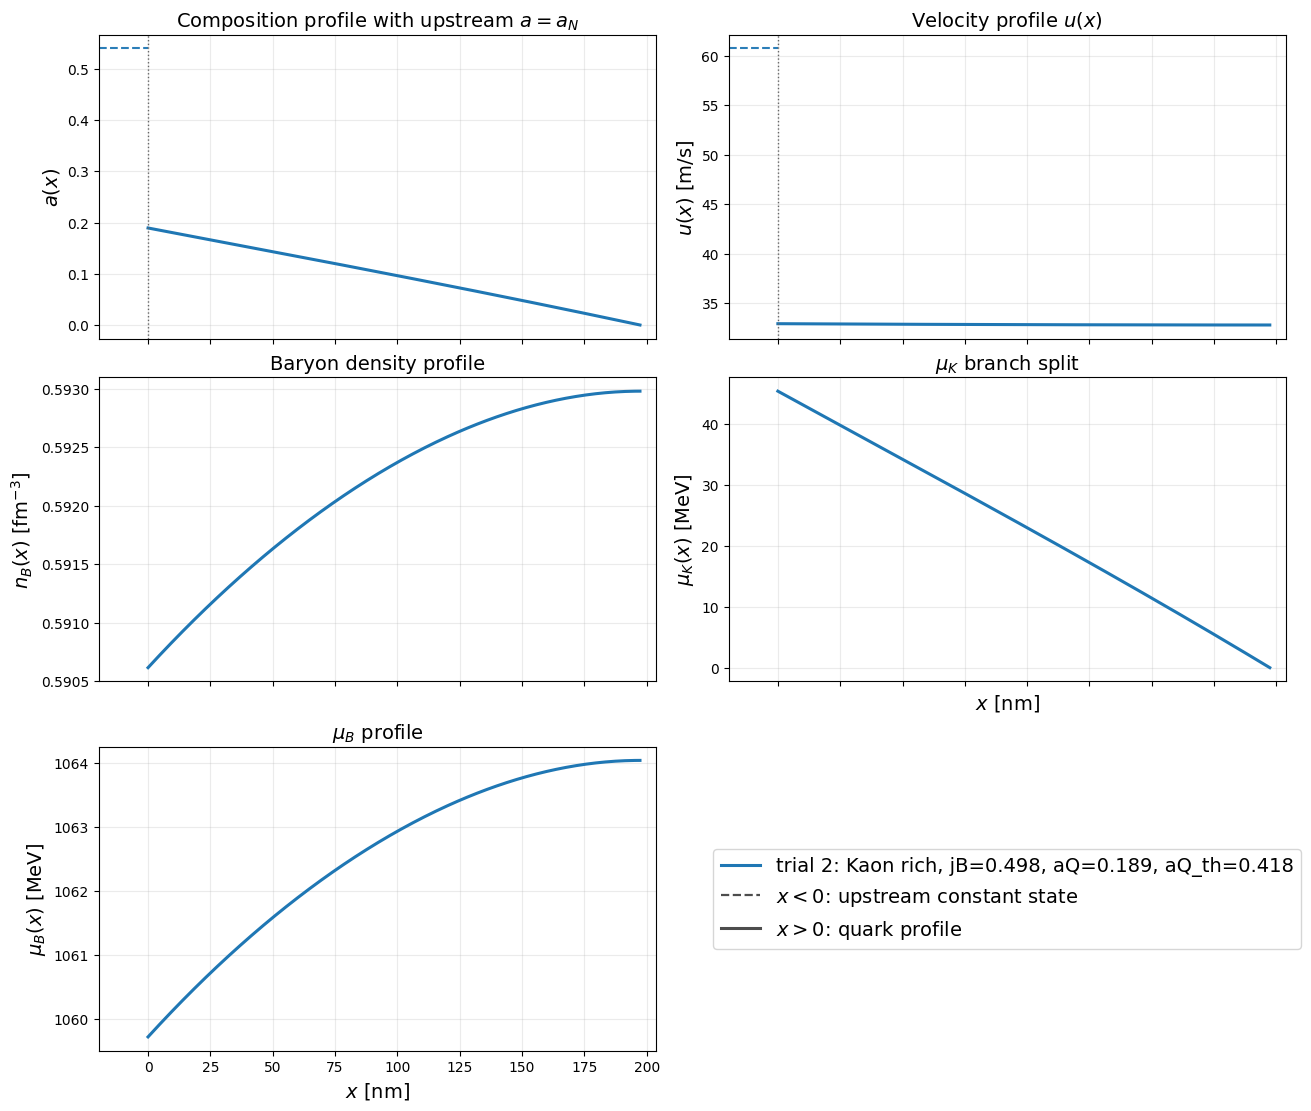

In [ ]:
# FORCE_UPDATE_CLUSTER_RESULTS_2026-04-05_F
import numpy as np
import matplotlib.pyplot as plt
import RMFsolver.constants as const
from matplotlib.lines import Line2D

if 'summary' not in globals():
    raise RuntimeError('Run the successful-trial shooting-summary cell just above this one first.')

results_root = summary['results_root']
run_dir = summary['run_dir']
config = summary['config']
rows_sorted = summary['rows']
if not rows_sorted:
    raise RuntimeError(f'No successful trials available in {run_dir.name}.')
row_by_id = summary.get('row_by_id', {row['trial_id']: row for row in rows_sorted})
print(f'Building profile summary from successful trials in: {run_dir.name}')

muK_thresh = 1e-3
rich_rows = [r for r in rows_sorted if r['muK_max'] >= muK_thresh]
poor_rows = [r for r in rows_sorted if r['muK_max'] < muK_thresh]

selected_ids = []
if rich_rows:
    selected_ids.append(rich_rows[0]['trial_id'])
if poor_rows:
    selected_ids.append(poor_rows[0]['trial_id'])
if rich_rows:
    selected_ids.append(max(rich_rows, key=lambda r: r['jB'])['trial_id'])
if poor_rows:
    selected_ids.append(max(poor_rows, key=lambda r: r['jB'])['trial_id'])

seen = set()
selected_ids = [tid for tid in selected_ids if not (tid in seen or seen.add(tid))]
print('Representative successful trials:', selected_ids)
for tid in selected_ids:
    row = row_by_id[tid]
    branch = 'poor' if row['muK_max'] < muK_thresh else 'rich'
    print(
        f"  trial {tid:2d}: branch={branch}, jB={row['jB']:.6f}, aQstar={row['aQstar']:.6f}, "
        f"aQstar_approx={row['aQstar_approx']:.6f}, muKmax={row['muK_max']:.3e}, "
        f"nB_span={row['nB_span']:.3e}, x_1pct={row['x_1pct']:.3e}"
    )

fig, axes = plt.subplots(3, 2, figsize=(13, 11), sharex=True, constrained_layout=True)
profile_cache = {}
x_left = np.linspace(-1.0e5, 0.0, 160)
fm_per_nm = 1.0e6
x_left_nm = x_left * const.MeV_fm / fm_per_nm
x_right_max_nm = 0.0
palette = plt.get_cmap('tab10').colors
color_by_tid = {tid: palette[i % len(palette)] for i, tid in enumerate(selected_ids)}
trial_handles = []

for tid in selected_ids:
    row = row_by_id[tid]
    branch = 'Kaon poor' if row['muK_max'] < muK_thresh else 'Kaon rich'
    color = color_by_tid[tid]
    label = (
        f"trial {tid}: {branch}, jB={row['jB']:.3f}, aQ={row['aQstar']:.3f}, "
        f"aQ_th={row['aQstar_approx']:.3f}"
    )
    trial_handles.append(Line2D([0], [0], color=color, lw=2.2, label=label))
    with np.load(row['npz_path_local']) as data:
        x_right = np.array(data['x'])
        x_plot_nm = x_right * const.MeV_fm / fm_per_nm
        x_right_max_nm = max(x_right_max_nm, float(np.max(x_plot_nm)))
        a_vals = np.array(data['a'])
        u_right_ms = np.array(data['u']) * const.m_per_sec
        nB_right_fm3 = np.array(data['nB']) / const.MeV_fm**3
        muK_vals = np.array(data['muK'])
        muB_vals = np.array(data['muB'])
        profile_cache[tid] = {
            'muB': muB_vals,
            'muK': muK_vals,
            'nB_fm3': nB_right_fm3,
        }
        a_left = np.full_like(x_left_nm, row['aN'])
        u_left_ms = np.full_like(x_left_nm, row['u_N'] * const.m_per_sec)

        axes[0, 0].plot(x_left_nm, a_left, lw=1.5, ls='--', alpha=0.95, color=color)
        axes[0, 0].plot(x_plot_nm, a_vals, lw=2.2, color=color)

        axes[0, 1].plot(x_left_nm, u_left_ms, lw=1.5, ls='--', alpha=0.95, color=color)
        axes[0, 1].plot(x_plot_nm, u_right_ms, lw=2.2, color=color)

        axes[1, 0].plot(x_plot_nm, nB_right_fm3, lw=2.2, color=color)
        axes[1, 1].plot(x_plot_nm, muK_vals, lw=2.2, color=color)
        axes[2, 0].plot(x_plot_nm, muB_vals, lw=2.2, color=color)

for i, tid_i in enumerate(selected_ids):
    for tid_j in selected_ids[i + 1:]:
        muB_diff = np.max(np.abs(profile_cache[tid_i]['muB'] - profile_cache[tid_j]['muB']))
        muK_diff = np.max(np.abs(profile_cache[tid_i]['muK'] - profile_cache[tid_j]['muK']))
        nB_diff = np.max(np.abs(profile_cache[tid_i]['nB_fm3'] - profile_cache[tid_j]['nB_fm3']))
        if muB_diff < 1e-8 and nB_diff < 1e-12 and muK_diff < 1e-4:
            print(
                f"  overlap note: trials {tid_i} and {tid_j} are visually on top of each other in muB/nB/muK "
                f"(max diffs: muB={muB_diff:.2e}, nB={nB_diff:.2e}, muK={muK_diff:.2e})"
            )

axes[0, 0].axvline(0.0, color='0.4', lw=1.0, ls=':')
axes[0, 1].axvline(0.0, color='0.4', lw=1.0, ls=':')
axes[0, 0].set_ylabel(r'$a(x)$', fontsize=14)
axes[0, 0].set_title(r'Composition profile with upstream $a=a_N$', fontsize=14)
axes[0, 1].set_ylabel(r'$u(x)$ [m/s]', fontsize=14)
axes[0, 1].set_title(r'Velocity profile $u(x)$', fontsize=14)
axes[1, 0].set_ylabel(r'$n_B(x)$ [fm$^{-3}$]', fontsize=14)
axes[1, 0].set_title('Baryon density profile', fontsize=14)
axes[1, 1].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=14)
axes[1, 1].set_xlabel(r'$x$ [nm]', fontsize=14)
axes[1, 1].set_title(r'$\mu_K$ branch split', fontsize=14)
axes[2, 0].set_ylabel(r'$\mu_B(x)$ [MeV]', fontsize=14)
axes[2, 0].set_xlabel(r'$x$ [nm]', fontsize=14)
axes[2, 0].set_title(r'$\mu_B$ profile', fontsize=14)
axes[2, 1].axis('off')
style_handles = [
    Line2D([0], [0], color='0.3', lw=1.6, ls='--', label=r'$x<0$: upstream constant state'),
    Line2D([0], [0], color='0.3', lw=2.2, ls='-', label=r'$x>0$: quark profile'),
]
axes[2, 1].legend(handles=trial_handles + style_handles, fontsize=14, loc='center')

x_pad_nm = 0.03 * max(x_right_max_nm - x_left_nm.min(), 1.0)
x_hi_nm = x_right_max_nm + x_pad_nm
for ax in [axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1], axes[2, 0]]:
    ax.grid(alpha=0.25)
    ax.set_xlim(x_left_nm.min(), x_hi_nm)

profile_pdf = results_root / f'profile_summary_{run_dir.name}_successful.pdf'
fig.savefig(profile_pdf, bbox_inches='tight')
print(f'Saved figure: {profile_pdf}')
plt.show()

